# Demo: phân loại nhóm liều warfarin bằng mạch lượng tử

Notebook dùng để trình bày trực tiếp. Chạy lần lượt từ trên xuống, tổng thời gian khoảng 1–2 phút.

1. Một bệnh nhân được biến thành 4 góc quay như thế nào.
2. Mạch lượng tử của QSVC, QSVC-product và VQC.
3. Hàm nhân lượng tử: điểm giống nhau giữa hai bệnh nhân, và ảnh hưởng của số lần đo (shots).
4. Huấn luyện nhanh các mô hình trên một fold của Development.
5. Dự đoán nhóm liều cho một bệnh nhân nhập tay.

Notebook chỉ dùng tập Development, không dùng Final Test. Hình mạch và hàm nhân được lưu vào `results/figures/`. Mô hình chỉ phục vụ nghiên cứu trên dữ liệu hồi cứu,
**không dùng để chỉ định liều điều trị**.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from qiskit.quantum_info import Statevector
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold

from src.dataset import CLASS_ORDER, load_dataset, site_labels, split_ids
from src.evaluation import classification_metrics, make_pipeline
from src.quantum_models import QuantumKernelSVC, VQCClassifier, feature_states, make_feature_map

FIG = ROOT / "results" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
NHOM = {0: "Thấp (≤ 21 mg/tuần)", 1: "Vừa (21–49 mg/tuần)", 2: "Cao (≥ 49 mg/tuần)"}
df = load_dataset(ROOT)
dev = df.loc[np.intersect1d(df.index.to_numpy(), split_ids(ROOT, "development"))]
y = dev["y"].to_numpy()
print(f"Development: {len(dev)} bệnh nhân; Thấp/Vừa/Cao = {np.bincount(y).tolist()}")

Development: 4328 bệnh nhân; Thấp/Vừa/Cao = [1429, 2349, 550]


## 1. Từ bệnh nhân đến góc quay

Mỗi bệnh nhân được mô tả bằng 4 đặc trưng theo công thức IWPC:
- **VKORC1:** số allele A của gen VKORC1 (0, 1 hoặc 2). Allele là một phiên bản của gen; allele A làm cơ thể
  nhạy với warfarin hơn, nên cần liều thấp hơn.
- **Cân nặng** (kg).
- **Tuổi** theo thập niên (60–69 tuổi là 6).
- **CYP2C9:** điểm hoạt tính của enzyme phân hủy warfarin (2 là bình thường, càng thấp thì thuốc càng lâu bị
  phân hủy).

Mỗi đặc trưng được co giãn về khoảng [0, π] để làm **góc quay** cho một qubit. Bước tiền xử lý chỉ học từ phần
huấn luyện của fold.

In [2]:
tr, va = next(StratifiedKFold(5, shuffle=True, random_state=42).split(dev, site_labels(dev)))
pre = make_pipeline(LogisticRegression(), "quantum", "domain", 4)[:-1].fit(dev.iloc[tr], y[tr])
feats = pre[:3].transform(dev.iloc[va[:5]])[:, :4]   # 3 bước đầu: tạo đặc trưng, điền thiếu
angles = pre.transform(dev.iloc[va[:5]])
pd.concat([pd.DataFrame(feats, columns=["VKORC1", "Cân nặng", "Tuổi (thập niên)", "CYP2C9"]),
           pd.DataFrame(angles, columns=[f"góc q{i}" for i in range(4)]),
           pd.Series([NHOM[c] for c in y[va[:5]]], name="Nhóm liều thật")], axis=1).round(2)

,VKORC1,Cân nặng,Tuổi (thập niên),CYP2C9,góc q0,góc q1,góc q2,góc q3,Nhóm liều thật
0,1.0,115.7,6.0,2.0,1.57,1.30,1.96,3.14,Cao (≥ 49 mg/tuần)
1,1.0,90.7,6.0,2.0,1.57,0.92,1.96,3.14,Vừa (21–49 mg/tuần)
2,1.0,72.6,5.0,1.0,1.57,0.64,1.57,1.57,Vừa (21–49 mg/tuần)
3,1.0,93.9,6.0,1.0,1.57,0.97,1.96,1.57,Thấp (≤ 21 mg/tuần)
4,1.0,95.3,6.0,2.0,1.57,0.99,1.96,3.14,Vừa (21–49 mg/tuần)


## 2. Mạch lượng tử

- **ZZ feature map (QSVC):** mỗi qubit qua cổng H rồi cổng pha P quay theo đặc trưng của nó; cặp qubit cạnh nhau được nối
  bằng CNOT để tạo **rối lượng tử** (entanglement), tức hai qubit không còn mô tả riêng rẽ được.
- **Z feature map (QSVC-product):** chỉ có cổng trên từng qubit, không có CNOT, nên không có rối lượng tử.
- **VQC:** feature map rồi tới khối RealAmplitudes có tham số huấn luyện được (các cổng RY và CNOT), lặp 2 lần.

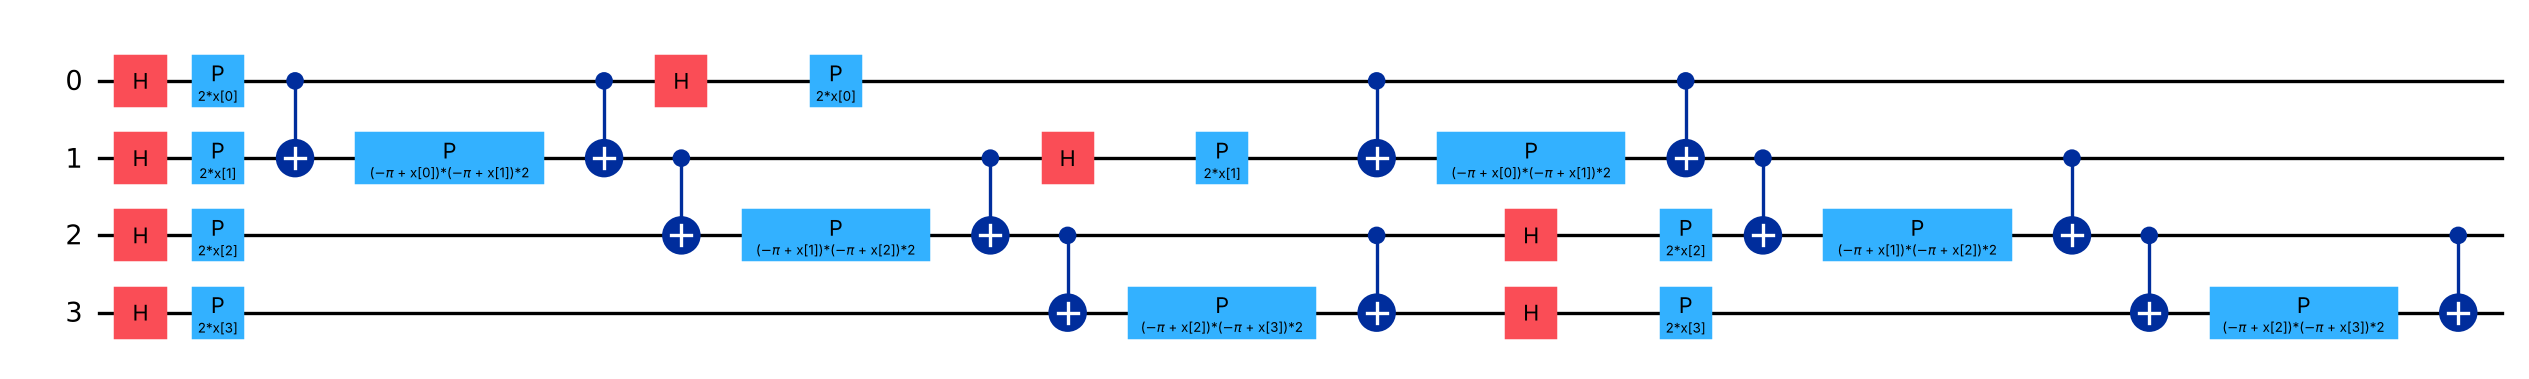

In [3]:
fm_zz = make_feature_map(4, "zz", 2, "linear")
fm_prod = make_feature_map(4, "product", 2)
fig = fm_zz.draw("mpl", fold=40, scale=0.6)
fig.savefig(FIG / "circuit_zz_feature_map.png", dpi=200, bbox_inches="tight")
fig

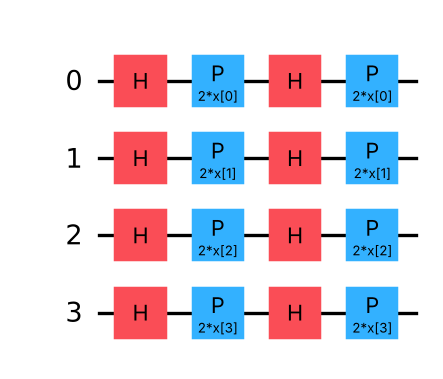

In [4]:
fig = fm_prod.draw("mpl", fold=40, scale=0.6)
fig.savefig(FIG / "circuit_z_feature_map.png", dpi=200, bbox_inches="tight")
fig

ZZ feature map  độ sâu =  19   số CNOT = 12
Z feature map   độ sâu =   4   số CNOT = 0
VQC (1 lớp)     độ sâu =  21   số CNOT = 15


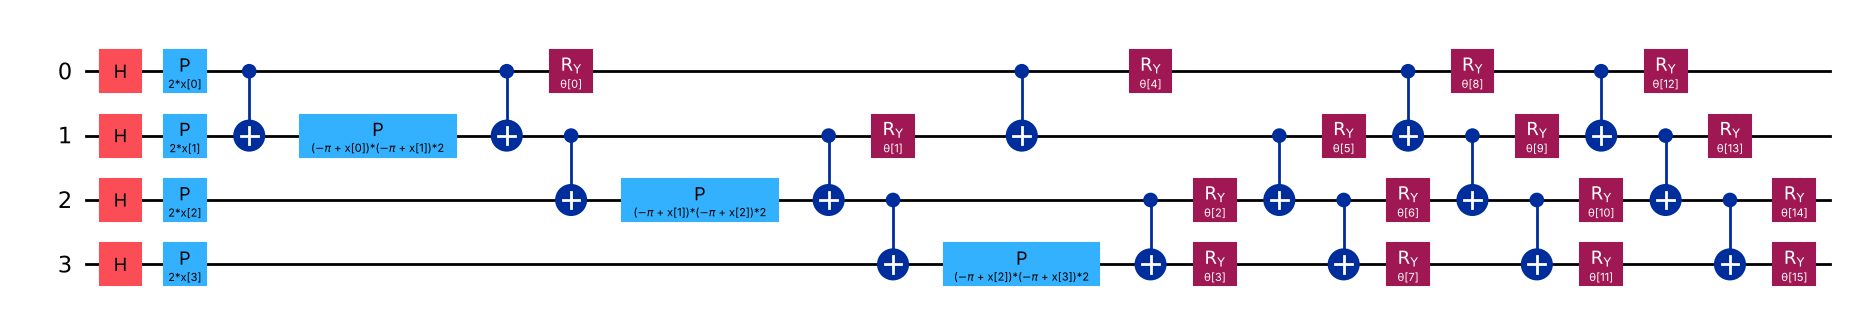

In [5]:
from qiskit.circuit.library import real_amplitudes
vqc_circuit = make_feature_map(4, "zz", 1, "linear").compose(real_amplitudes(4, reps=3, entanglement="linear"))
for name, c in [("ZZ feature map", fm_zz), ("Z feature map", fm_prod), ("VQC (1 lớp)", vqc_circuit)]:
    d = c.decompose(reps=3)
    print(f"{name:15s} độ sâu = {d.depth():3d}   số CNOT = {d.count_ops().get('cx', 0)}")
fig = vqc_circuit.draw("mpl", fold=40, scale=0.5)
fig.savefig(FIG / "circuit_vqc_one_layer.png", dpi=200, bbox_inches="tight")
fig

## 3. Đo một bệnh nhân: xác suất và shots

Sau mạch, đo 4 qubit cho ra một chuỗi 4 bit. Xác suất ra mỗi chuỗi bằng bình phương độ lớn biên độ
(quy tắc Born). Máy thật không cho ra xác suất trực tiếp: phải chạy mạch nhiều lần (shots) rồi đếm.

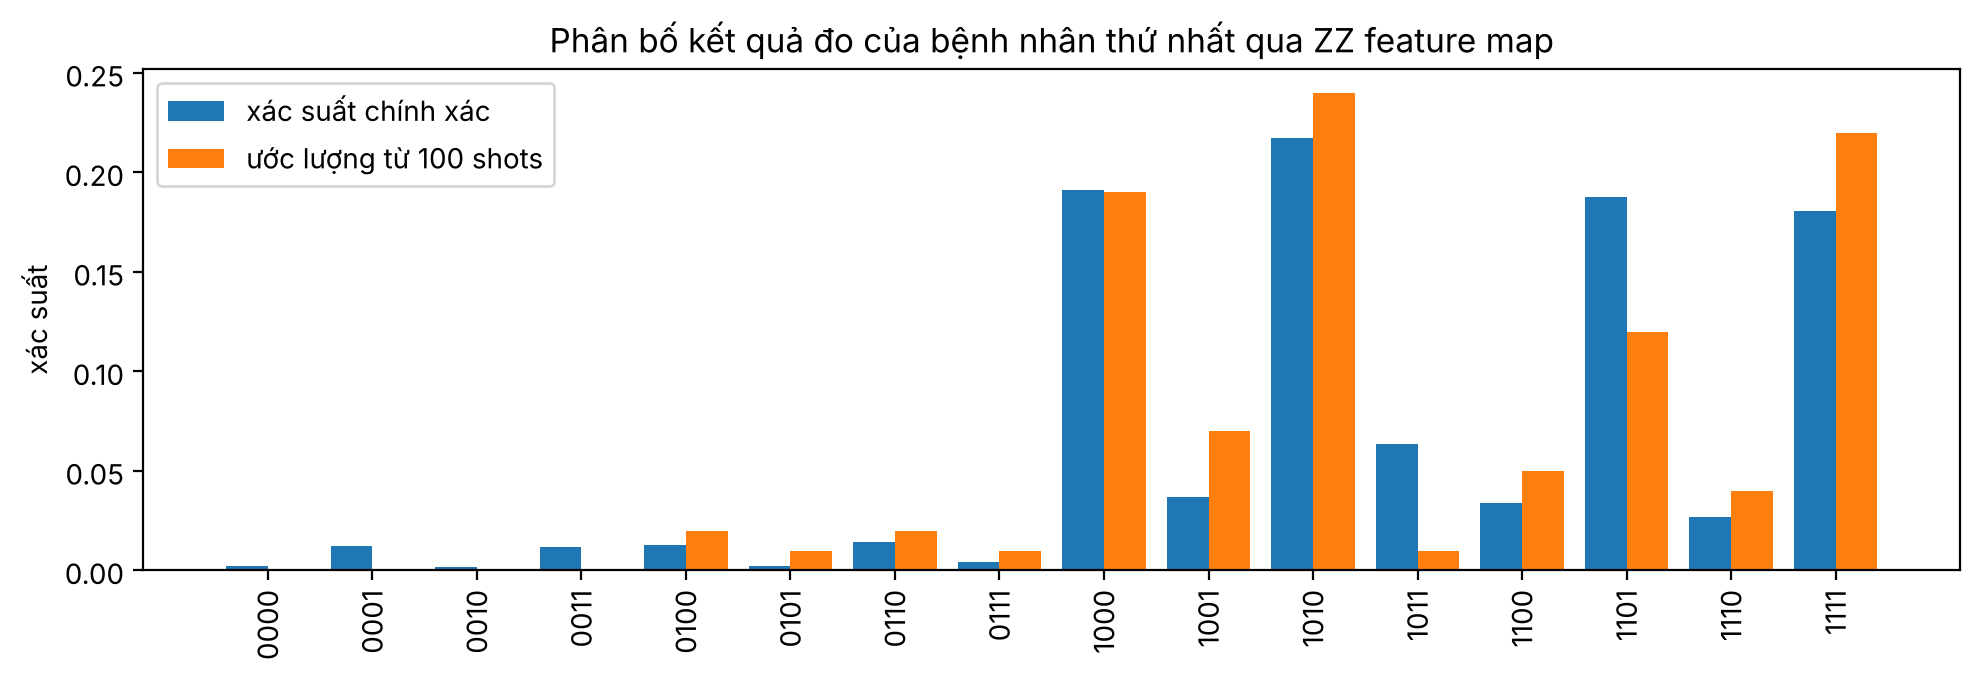

In [6]:
x0 = 0.5 * angles[0]   # bandwidth 0.5 như VQC
probs = Statevector(fm_zz.assign_parameters(x0)).probabilities()
rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(10, 3.5))
labels = [format(i, "04b") for i in range(16)]
ax.bar(np.arange(16) - 0.2, probs, width=0.4, label="xác suất chính xác")
ax.bar(np.arange(16) + 0.2, rng.multinomial(100, probs) / 100, width=0.4, label="ước lượng từ 100 shots")
ax.set_xticks(range(16), labels, rotation=90); ax.set_ylabel("xác suất"); ax.legend()
ax.set_title("Phân bố kết quả đo của bệnh nhân thứ nhất qua ZZ feature map")
plt.tight_layout(); plt.show()

## 4. Hàm nhân lượng tử: hai bệnh nhân giống nhau đến mức nào

Hàm nhân K(a, b) = |⟨φ(a)|φ(b)⟩|² đo mức giống nhau giữa trạng thái lượng tử của hai bệnh nhân (1 là giống hệt).
Trên máy thật, K được ước lượng bằng mạch U(a) rồi U(b)†, đếm tỉ lệ lần đo ra 0000.

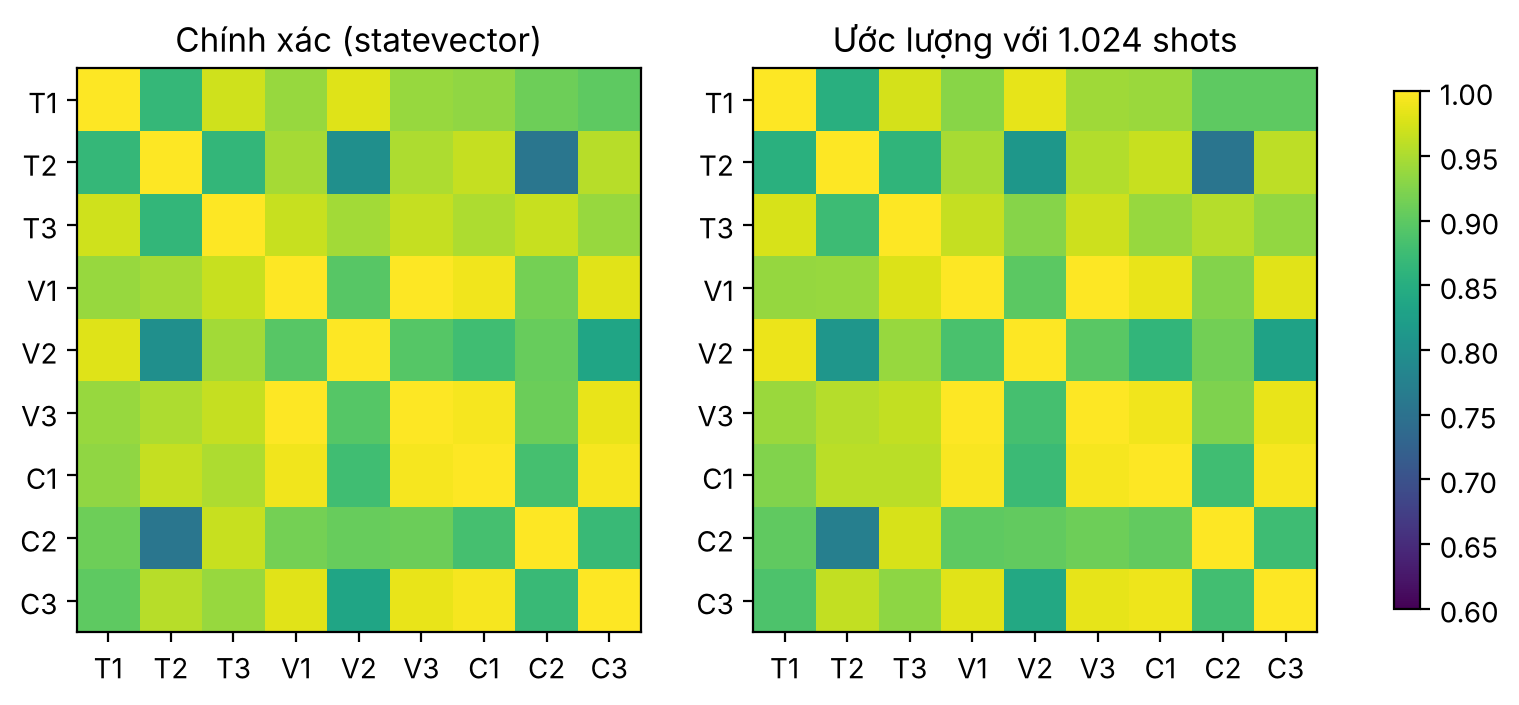

Trung bình ngoài đường chéo: 0.926; sai lệch trung bình do shots: 0.0064


In [7]:
idx = np.concatenate([va[y[va] == c][:3] for c in range(3)])   # 3 bệnh nhân mỗi nhóm
A = pre.transform(dev.iloc[idx])
S = feature_states(0.05 * A, fm_zz)                              # bandwidth 0.05 như QSVC đã chọn
K = np.abs(S.conj() @ S.T) ** 2
K_shots = rng.binomial(1024, K) / 1024
fig, ax = plt.subplots(1, 2, figsize=(10, 4.2))
names = [f"{['T', 'V', 'C'][c]}{i + 1}" for c in range(3) for i in range(3)]
for a, M, t in [(ax[0], K, "Chính xác (statevector)"), (ax[1], K_shots, "Ước lượng với 1.024 shots")]:
    im = a.imshow(M, vmin=0.6, vmax=1, cmap="viridis")
    a.set_xticks(range(9), names); a.set_yticks(range(9), names); a.set_title(t)
fig.colorbar(im, ax=ax, shrink=0.8)
fig.savefig(FIG / "kernel_heatmap_shots.png", dpi=200, bbox_inches="tight")
plt.show()
off = ~np.eye(9, dtype=bool)
print(f"Trung bình ngoài đường chéo: {K[off].mean():.3f}; sai lệch trung bình do shots: {np.abs(K_shots - K)[off].mean():.4f}")

T, V, C là các nhóm Thấp, Vừa, Cao. Hầu hết giá trị nằm gần 1, tức là các bệnh nhân trông rất giống nhau trong
không gian lượng tử (hàm nhân bị tập trung). Thông tin phân loại nằm ở những chênh lệch nhỏ, nên sai số do shots
dù nhỏ cũng đủ làm mô hình kém đi (xem `results/noise/`).

## 5. Huấn luyện nhanh trên một fold của Development

Dùng fold 0 (3.462 người huấn luyện, 866 người kiểm định) với siêu tham số đã chọn trong thí nghiệm chính.
VQC mất khoảng 40 giây.

In [8]:
from sklearn.svm import SVC

MODELS = {
    "LR": (LogisticRegression(C=100, max_iter=5000, class_weight="balanced"), "classical"),
    "SVM": (SVC(C=10, gamma=0.01, class_weight="balanced"), "classical"),
    "QSVC-product": (QuantumKernelSVC(feature_map="product", bandwidth=0.1, C=10), "quantum"),
    "QSVC": (QuantumKernelSVC(feature_map="zz", bandwidth=0.05, C=10), "quantum"),
    "VQC": (VQCClassifier(layers=2, reps=3, bandwidth=0.5, maxiter=250, seed=0), "quantum"),
}
fitted, rows = {}, []
for name, (model, kind) in MODELS.items():
    t0 = time.perf_counter()
    pipe = make_pipeline(model, kind, "domain", 4).fit(dev.iloc[tr], y[tr])
    m = classification_metrics(y[va], pipe.predict(dev.iloc[va]))
    fitted[name] = pipe
    rows.append({"mô hình": name, "Macro-F1": m["macro_f1"], "accuracy": m["accuracy"],
                 "recall Cao": m["recall_high"], "thời gian (giây)": time.perf_counter() - t0})
pd.DataFrame(rows).round(3)

,mô hình,Macro-F1,accuracy,recall Cao,thời gian (giây)
0,LR,0.544,0.558,0.706,0.052
1,SVM,0.566,0.580,0.752,0.354
2,QSVC-product,0.564,0.579,0.725,2.290
3,QSVC,0.550,0.566,0.706,3.637
4,VQC,0.514,0.527,0.725,40.819


## 6. Dự đoán cho một bệnh nhân nhập tay

Đổi các giá trị trong ô dưới để thử. Kiểu gen ghi theo dữ liệu IWPC, ví dụ VKORC1 `G/G`, `A/G`, `A/A` và
CYP2C9 `*1/*1`, `*1/*2`, `*1/*3`, `*2/*3`, `*3/*3`. Tuổi ghi theo nhóm, ví dụ `60 - 69`.

In [9]:
def du_doan(vkorc1, cyp2c9, tuoi, can_nang, chieu_cao=np.nan, gioi_tinh="male"):
    benh_nhan = pd.DataFrame([{
        "VKORC1 -1639 consensus": vkorc1, "VKORC1 1173 consensus": np.nan, "CYP2C9 consensus": cyp2c9,
        "Age": tuoi, "Weight (kg)": can_nang, "Height (cm)": chieu_cao, "Gender": gioi_tinh}])
    return pd.Series({name: NHOM[int(p.predict(benh_nhan)[0])] for name, p in fitted.items()}, name="dự đoán")

pd.concat({
    "A/A, *1/*3, 70–79 tuổi, 60 kg": du_doan("A/A", "*1/*3", "70 - 79", 60),
    "A/A, *3/*3, 70–79 tuổi, 55 kg": du_doan("A/A", "*3/*3", "70 - 79", 55),
    "A/G, *1/*1, 50–59 tuổi, 75 kg": du_doan("A/G", "*1/*1", "50 - 59", 75),
    "G/G, *1/*1, 30–39 tuổi, 100 kg": du_doan("G/G", "*1/*1", "30 - 39", 100),
}, axis=1).T

,LR,SVM,QSVC-product,QSVC,VQC
"A/A, *1/*3, 70–79 tuổi, 60 kg",Thấp (≤ 21 mg/tuần),Thấp (≤ 21 mg/tuần),Thấp (≤ 21 mg/tuần),Thấp (≤ 21 mg/tuần),Thấp (≤ 21 mg/tuần)
"A/A, *3/*3, 70–79 tuổi, 55 kg",Thấp (≤ 21 mg/tuần),Thấp (≤ 21 mg/tuần),Thấp (≤ 21 mg/tuần),Thấp (≤ 21 mg/tuần),Cao (≥ 49 mg/tuần)
"A/G, *1/*1, 50–59 tuổi, 75 kg",Vừa (21–49 mg/tuần),Vừa (21–49 mg/tuần),Vừa (21–49 mg/tuần),Vừa (21–49 mg/tuần),Cao (≥ 49 mg/tuần)
"G/G, *1/*1, 30–39 tuổi, 100 kg",Cao (≥ 49 mg/tuần),Cao (≥ 49 mg/tuần),Cao (≥ 49 mg/tuần),Cao (≥ 49 mg/tuần),Cao (≥ 49 mg/tuần)


Bệnh nhân có 2 allele A ở VKORC1, CYP2C9 hoạt tính thấp, lớn tuổi và nhẹ cân thường cần liều thấp; bệnh nhân
không có allele A, CYP2C9 bình thường, trẻ và nặng cân thường cần liều cao. LR, SVM, QSVC-product và QSVC cho kết
quả đúng với xu hướng này.

VQC thì khác: với bệnh nhân A/A, *3/*3 (kiểu gen nhạy với warfarin nhất), VQC dự đoán nhóm Cao, trong khi chỉ đổi
sang *1/*3 thì VQC lại dự đoán nhóm Thấp. Kiểu gen *3/*3 rất hiếm (13 trong 4.328 bệnh nhân của Development, 11 người
thuộc nhóm Thấp), nên VQC có ít dữ liệu ở vùng này. Đây là một ví dụ cụ thể cho thấy vì sao VQC có Macro-F1 thấp nhất.

In [10]:
# Trên fold kiểm định: tỉ lệ bệnh nhân nhóm Vừa bị dự đoán thành nhóm Cao
vua = y[va] == 1
for name in ["LR", "QSVC", "VQC"]:
    p = fitted[name].predict(dev.iloc[va])
    print(f"{name:5s} dự đoán Cao cho {np.mean(p[vua] == 2):.0%} bệnh nhân nhóm Vừa")

LR    dự đoán Cao cho 31% bệnh nhân nhóm Vừa


QSVC  dự đoán Cao cho 34% bệnh nhân nhóm Vừa


VQC   dự đoán Cao cho 37% bệnh nhân nhóm Vừa
